# Goal

This is the "too long; didn't read" (tldr) explanation of the code, which includes only the bare minimum needed to get started. I do highly recommend going through all the other tutorials, though.

# Imports

In [1]:
import sys
sys.path.append("..") #Point this to where the ensor.py file is located
from ensor import *

# Code

### Part 1: Open a fits file and load the bands you want to visualize
You might need to customize this to fit your own image. Just make sure each band is in nanomaggies (https://www.sdss3.org/dr8/algorithms/magnitudes.php).

In [9]:
#Opening a fits file with gri bands. 
images_dir = '../data/'

fileloc = f'{images_dir}/Legacy/zoom_in.fits'

hdul = fits.open(fileloc)

g = hdul[0].data[0] #Units need to be in nanomaggy!
r = hdul[0].data[1]
z = hdul[0].data[2]

### Part 2: Create a greyscale image

This package is centered around the `make_image` function. We will use it here to create a greyscale image of the r-band, using an `asinh` scaling/stretch. The `weights` dictionary decides how much weight to give each band in each of the red, green, and blue channels. For a greyscale image, this can all be equal to 1.

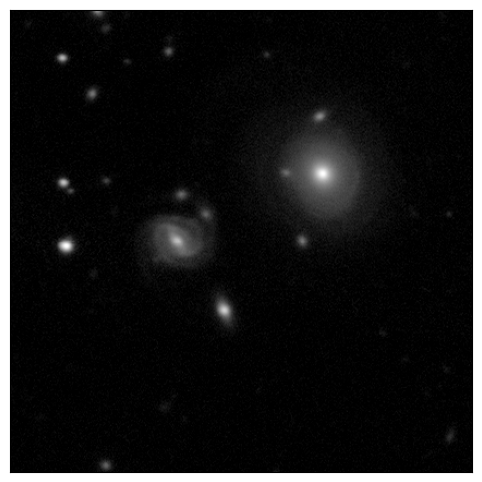

In [10]:
imgs = [r]
bands = ['r']

weights = dict(
    r = (1,1,1) #rgb
)

greyscale = make_image(imgs, bands, weights = weights, func = asinh)
plot_image(greyscale)

### Part 3: Create a colour image

We will now create a colour image. The weights are the Legacy/SDSS preset, and they basically map the g-band to blue channel, the r-band to the green channel, and the i-band to the red channel.

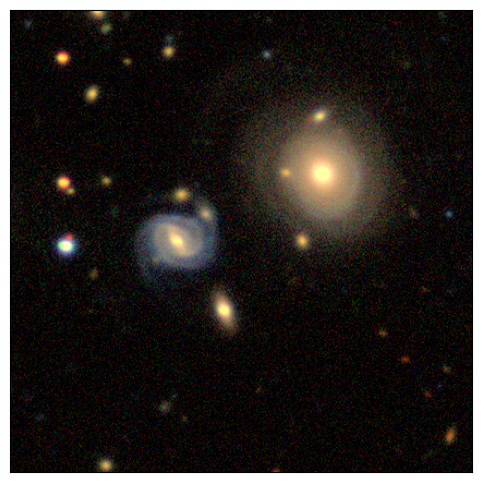

In [19]:
imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 0, 6.0), 
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

rgb = make_image(imgs, bands, weights, func = asinh)
plot_image(rgb)

And that's it! I strongly recommend going through the other tutorials for more information and customization options. Also, run the below to get more information on the main function of the code:

In [12]:
help(make_image)

Help on function make_image in module ensor:

make_image(
    imgs,
    bands,
    weights=None,
    func=None,
    clip=True,
    offset=0.0,
    eps=1e-10,
    apply_lupton=True,
    **func_kwargs
)
    DESCRIPTION
    -----------
    A (hopefully) easy-to-use function to create greyscale or colour (rgb) images from astronomical observations.

    The input is assumed to be in nanomaggies (https://www.sdss3.org/dr8/algorithms/magnitudes.php), but will work in principle with any linear flux unit.

    This is based on Lupton+2004 (https://arxiv.org/abs/astro-ph/0312483). Also inspired by the Legacy/SDSS method (https://github.com/legacysurvey/legacypipe/blob/f77ed93c4e9df40e27aec132fd9a9db0c78678d5/py/legacypipe/survey.py#L719) and Astropy's make_lupon_rgb (https://docs.astropy.org/en/stable/api/astropy.visualization.make_lupton_rgb.html).



    PARAMETERS
    ----------
    imgs : list
        A list of the astronomical observations in different bands, e.g., [g,r,i].

    bands : li